## Phase 0–1: Load and inspect

Connect to the DB, load both tables, check shape/dtypes/duplicates/missingness/cardinality.

In [2]:
import sqlite3
import pandas as pd
import numpy as np
import re

conn = sqlite3.connect("data/hotel.db")
bookings = pd.read_sql("SELECT * FROM bookings", conn)
reviews  = pd.read_sql("SELECT * FROM reviews", conn)

bookings.info()
bookings.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118549 entries, 0 to 118548
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   Unnamed: 0                      118549 non-null  object
 1   booking_id                      118549 non-null  object
 2   client_email                    118549 non-null  object
 3   hotel                           118549 non-null  object
 4   is_canceled                     118549 non-null  object
 5   lead_time                       118549 non-null  object
 6   arrival_date_year               118549 non-null  object
 7   arrival_date_month              118549 non-null  object
 8   arrival_date_week_number        118549 non-null  object
 9   arrival_date_day_of_month       118549 non-null  object
 10  stays_in_weekend_nights         118549 non-null  object
 11  stays_in_week_nights            118549 non-null  object
 12  adults                        

,Unnamed: 0,booking_id,client_email,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,promo_code
0,112427,SG134998,jia.ng9250@outlook.com,Airport Hotel,0,94,2025,May,20,16,...,240.0,,0,Transient,230,0,1,Check-Out,2025-05-19 00:00:00,EARLYBIRD
1,95089,SG109835,david.kumar3843@hotmail.com,Airport Hotel,1,103,2025,March,13,27,...,495.0,Kallang Industries,0,Transient,167.9,0,0,Canceled,2024-12-23 00:00:00,
2,78527,SG207272,mei.low3636@icloud.com,City Hotel,0,83,2025,Apr,17,23,...,9.0,,0,Transient,27.6,0,2,Check-Out,2025-04-28 00:00:00,STAY3PAY2
3,76840,SG115106,arjun.ong1474@yahoo.com.sg,Airport Hotel,0,48,2023,August,35,27,...,196.0,,0,Transient,246.1,1,0,Check-Out,2023-08-31 00:00:00,FLASH
4,1167,SG182301,arjun.kumar398@icloud.com,City Hotel,0,1,2024,March,11,9,...,9.0,,0,Transient-Party,218.5,0,0,Check-Out,2024-03-10 00:00:00,


In [3]:
reviews.info()
reviews.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17583 entries, 0 to 17582
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   client_email  17583 non-null  object
 1   rating        17583 non-null  object
 2   comments      17583 non-null  object
dtypes: object(3)
memory usage: 412.2+ KB


,client_email,rating,comments
0,farah.wong8097@gmail.com,4,"A hassle-free stay. The room was bright, nothi..."
1,grace.goh4995@hotmail.com,5,A world-class stay — the staff went above and ...
2,arjun.iskandar6575@icloud.com,5,Couldn't have asked for more — the team could ...
3,daniel.raj4258@outlook.com,4,"A fuss-free stay. Check-in was smooth, a relia..."
4,zhen.koh776@icloud.com,5,An unforgettable stay. The team could not do e...


In [4]:
# duplicates
print("dup booking_id:", bookings["booking_id"].duplicated().sum())
print("full-row dups:", bookings.duplicated().sum())

dup booking_id: 353
full-row dups: 353


In [5]:
print("dup client_email:", reviews["client_email"].duplicated().sum())
print("full-row dups:", reviews.duplicated().sum())

dup client_email: 51
full-row dups: 51


In [6]:
# missingness
(bookings.isna().mean() * 100).round(1).sort_values(ascending=False).loc[lambda s: s > 0]

Series([], dtype: float64)

In [7]:
(reviews.isna().mean() * 100).round(1).sort_values(ascending=False).loc[lambda s: s > 0]

Series([], dtype: float64)

In [8]:
# cardinality of categoricals
cat_cols = bookings.select_dtypes(include="object").columns
for col in cat_cols:
    n = bookings[col].nunique()
    print(f"\n{col} ({n}):\n{bookings[col].value_counts(dropna=False)}")


Unnamed: 0 (118196):
Unnamed: 0
74318     2
26413     2
36025     2
20207     2
12357     2
         ..
100022    1
116622    1
43072     1
74783     1
15947     1
Name: count, Length: 118196, dtype: int64

booking_id (118196):
booking_id
SG146903    2
SG199127    2
SG204618    2
SG128905    2
SG110947    2
           ..
SG169217    1
SG161886    1
SG127534    1
SG118461    1
SG120283    1
Name: count, Length: 118196, dtype: int64

client_email (118196):
client_email
grace.das2087@icloud.com       2
kai.rahman1126@icloud.com      2
omar.das3258@gmail.com         2
chloe.rahman1316@icloud.com    2
samuel.chan1911@outlook.com    2
                              ..
tanvir.ong6060@gmail.com       1
li.kumar4270@yahoo.com.sg      1
mira.kumar566@yahoo.com.sg     1
tanvir.lee9465@outlook.com     1
kai.lim9429@yahoo.com.sg       1
Name: count, Length: 118196, dtype: int64

hotel (2):
hotel
City Hotel       79228
Airport Hotel    39321
Name: count, dtype: int64

is_canceled (6):
is_canceled
0 

In [9]:
# cardinality of categoricals
cat_cols_2 = reviews.select_dtypes(include="object").columns
for col in cat_cols_2:
    n = reviews[col].nunique()
    print(f"\n{col} ({n}):\n{reviews[col].value_counts(dropna=False)}")


client_email (17532):
client_email
farah.wan8037@hotmail.com         2
mei.ong1861@icloud.com            2
mira.yeo505@outlook.com           2
hakim.see7199@icloud.com          2
samuel.low5735@outlook.com        2
                                 ..
samuel.iskandar3075@icloud.com    1
yuki.low1873@hotmail.com          1
li.yeo5206@gmail.com              1
ling.lim9558@gmail.com            1
grace.wong2947@gmail.com          1
Name: count, Length: 17532, dtype: int64

rating (7):
rating
4    10635
5     4594
3     1553
2      527
1      100
0       87
6       87
Name: count, dtype: int64

comments (16839):
comments
                                                                                       332
Stayed over the Taylor Swift weekend, decent room and an easy trip to the concert.      49
Comfortable and convenient, minor niggles only.                                         48
In town for the Eras Tour; good stay, though the area was busy with concert crowds.     44
Here for the

**Findings — load and inspect**

- **Shape:** bookings 118,549 rows × 36 columns; reviews 17,583 rows × 3 columns.
- **dtypes:** every column in both tables loaded as `object`, including numerics
  (`lead_time`, `adr`, `arrival_date_year`) — SQLite's loose typing means nothing is
  usable as-is; explicit casting is required before any calculation.
- **Duplicates:** 353 duplicate `booking_id`s in bookings, all of which are also full-row
  duplicates — exact copies, not distinct bookings reusing an ID. Reviews: 51 duplicate
  `client_email`s, also all full-row duplicates. Both dropped in cleaning.
- **Missingness:** `isna()` reports zero missing values in either table — but this is a
  false negative. `agent`, `company` and `promo_code` store missing values as empty
  strings, not NaN, so pandas doesn't see them as missing. Confirmed and fixed in cleaning.
- **Cardinality:** several categoricals have far more levels than the business definition
  allows — `meal` 41 (should be 5), `market_segment` 66 (should be 8), `distribution_channel`
  38 (should be 4), `customer_type` 41 (should be 4), `deposit_type` 26 (should be 3),
  `country` 140. These are case, spacing and typo variants of the same values (e.g.
  " No  Deposit ", "NO DEPOSIT", "No-Deposit"), not genuinely new categories — normalised
  in cleaning. `is_canceled`, the target, has 6 encodings (`0`/`1`/`Yes`/`No`/`true`/`false`)
  that must be unified before any labelling. `agent` (333) and `company` (241) are
  high-cardinality identifiers, not usable categoricals directly.

In [10]:
# reserved vs assigned room type mismatch
room_mismatch = bookings["reserved_room_type"] != bookings["assigned_room_type"]
print("mismatch rate:", room_mismatch.mean().round(3))

# room types only ever seen as 'assigned', never as 'reserved'
assigned_only = set(bookings["assigned_room_type"]) - set(bookings["reserved_room_type"])
print("assigned-only room types:", assigned_only)

# is_canceled has mixed encodings (0/1, true/false, Yes/No) — normalize locally for this check
# (needs a proper global fix during cleaning)
canceled_map = {"0": 0, "1": 1, "true": 1, "false": 0, "Yes": 1, "No": 0}
is_canceled_num = bookings["is_canceled"].map(canceled_map)

# cancellation rate by mismatch flag
bookings.assign(room_type_mismatch=room_mismatch, is_canceled_num=is_canceled_num) \
    .groupby("room_type_mismatch")["is_canceled_num"].mean()

mismatch rate: 0.122
assigned-only room types: {'I', 'K'}


room_type_mismatch
False    0.407155
True     0.054514
Name: is_canceled_num, dtype: float64

## Phase 2: Cleaning

Fix issues found above: leftover index column, all columns stored as text, inconsistent
target encoding, hidden missing values stored as empty strings, duplicate rows, and
invalid review ratings. Cleaning fixes objectively wrong values; encoding/scaling
decisions are deferred to the pipeline, where they are fitted on training data only.

In [11]:
df = bookings.copy()

# ── 1. Structural ─────────────────────────────────────────────
df = df.drop(columns="Unnamed: 0").drop_duplicates()          # 353 exact dups
df["is_canceled"] = df["is_canceled"].map(
    {"0": 0, "No": 0, "false": 0, "1": 1, "Yes": 1, "true": 1}).astype(int)

# ── 2. Generic categorical normaliser ─────────────────────────
# Collapses the case/whitespace/typo variants: " No  Deposit ", "NO DEPOSIT",
# "No-Deposit" all reduce to the key "no deposit", then map to canonical.
JUNK = {"", "-", "--", "unknown", "null", "na", "n/a", "none"}

def normalise(series, mapping, junk_to=np.nan):
    key = (series.astype(str)
                 .str.strip()
                 .str.replace(r"[\s\-]+", " ", regex=True)   # collapse spaces & hyphens
                 .str.lower())
    out = key.map(mapping)
    out[key.isin(JUNK)] = junk_to
    return out

meal_map = {"bb": "BB", "hb": "HB", "fb": "FB", "sc": "SC", "undefined": "Undefined"}
df["meal"] = normalise(df["meal"], meal_map, junk_to="Undefined")

deposit_map = {"no deposit": "No Deposit", "no depost": "No Deposit",
               "non refund": "Non Refund", "refundable": "Refundable"}
df["deposit_type"] = normalise(df["deposit_type"], deposit_map)

cust_map = {"transient": "Transient", "transiant": "Transient",
            "transient party": "Transient-Party",
            "contract": "Contract", "group": "Group"}
df["customer_type"] = normalise(df["customer_type"], cust_map)

seg_map = {"online ta": "Online TA", "offline ta/to": "Offline TA/TO",
           "offline ta/t0": "Offline TA/TO",          # zero-for-O typo
           "direct": "Direct", "groups": "Groups", "corporate": "Corporate",
           "complementary": "Complementary", "aviation": "Aviation",
           "undefined": "Undefined"}
df["market_segment"] = normalise(df["market_segment"], seg_map)

chan_map = {"ta/to": "TA/TO", "direct": "Direct",
            "corporate": "Corporate", "gds": "GDS", "undefined": "Undefined"}
df["distribution_channel"] = normalise(df["distribution_channel"], chan_map)

# After each: verify nothing fell through the map
for col in ["meal", "deposit_type", "customer_type", "market_segment", "distribution_channel"]:
    n_unmapped = df[col].isna().sum()
    print(f"{col}: {df[col].nunique()} levels, {n_unmapped} unmapped/junk -> NaN")

# ── 3. Months: short forms -> long ────────────────────────────
month_map = {"Jan": "January", "Feb": "February", "Mar": "March", "Apr": "April",
             "Jun": "June", "Jul": "July", "Aug": "August", "Sep": "September",
             "Oct": "October", "Nov": "November", "Dec": "December"}
df["arrival_date_month"] = df["arrival_date_month"].str.strip().replace(month_map)

# ── 4. lead_time: strip text like "30 days", then numeric ─────
df["lead_time"] = pd.to_numeric(
    df["lead_time"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")

# ── 5. country: junk -> NaN, word-forms -> ISO, then fill ─────
country_fix = {"Australia": "AUS", "Malaysia": "MYS", "Singapore": "SGP",
               "Indonesia": "IDN", "China": "CHN", "Other": "OTH",
               "India": "IND", "Japan": "JPN", "United States": "USA",
               "Hong Kong": "HKG", "United Kingdom": "GBR", "Thailand": "THA",
               "South Korea": "KOR", "Philippines": "PHL", "Myanmar": "MMR",
               "Taiwan": "TWN", "Vietnam": "VNM", "New Zealand": "NZL"}
c = df["country"].astype(str).str.strip()
c = c.replace(country_fix)
c[c.str.lower().isin(JUNK)] = np.nan
df["country"] = c.fillna("OTH")
# sanity: everything should now be a 3-letter code
print("non-ISO country values:", df.loc[~df["country"].str.fullmatch(r"[A-Z]{3}"), "country"].unique())

# ── 6. Remaining numerics ─────────────────────────────────────
num_cols = ["arrival_date_year", "arrival_date_day_of_month",
            "stays_in_weekend_nights", "stays_in_week_nights", "adults",
            "children", "babies", "is_repeated_guest", "previous_cancellations",
            "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "required_car_parking_spaces",
            "total_of_special_requests"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# ── 7. Blank strings elsewhere -> NaN; agent/company -> flags ─
df = df.replace("", np.nan)
df["has_agent"]   = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)
df["promo_code"]  = df["promo_code"].fillna("NONE")

# ── 8. Drop columns ───────────────────────────────────────────
DROP_IN_EDA = [
    "booking_id",                # pure identifier; only needed for duplicate check above
    "arrival_date_week_number",  # 490 corrupt values (blank/unknown/-); redundant with month+day
    "reservation_status_date",   # set when outcome is recorded -> leakage; mixed formats not worth repairing
    "agent",                     # high-cardinality ID; replaced by has_agent flag
    "company",                   # high-cardinality ID; replaced by has_company flag
]
df = df.drop(columns=DROP_IN_EDA)
# reservation_status kept for now — needed for the leakage crosstab — dropped at modelling.

# Kept in the dataframe for EDA use, but excluded from model features.
# Rule: a feature must be knowable 7 days before arrival (the prediction point).
EXCLUDE_FROM_MODEL = [
    "is_canceled",          # the target itself
    "reservation_status",   # target re-encoded (proven by crosstab); kept only for that proof
    "client_email",         # identifier; kept as join key to reviews for descriptive analysis
    "assigned_room_type",   # assigned at check-in -> unknown at T-7
]

print(df.shape)

meal: 5 levels, 76 unmapped/junk -> NaN
deposit_type: 3 levels, 0 unmapped/junk -> NaN
customer_type: 4 levels, 537 unmapped/junk -> NaN
market_segment: 8 levels, 668 unmapped/junk -> NaN
distribution_channel: 5 levels, 495 unmapped/junk -> NaN
non-ISO country values: []
(118196, 32)


In [12]:
# --- reviews ---
rv = reviews.drop_duplicates().copy()
rv["rating"] = pd.to_numeric(rv["rating"], errors="coerce")
rv = rv[rv["rating"].between(1, 5)]   # 0 and 6 are impossible on a 1-5 scale -> drop (174 rows)
print(rv.shape)

(17359, 3)


### Unmapped categorical values

The normaliser sent junk values (blank, "-", "unknown", "NULL") to NaN: meal 76, customer_type 537, market_segment 668, distribution_channel 495 — each under 0.6% of rows.
Rather than dropping these rows or fabricating a value via mode imputation, we keep them as an explicit "Unknown" level. This loses no data and lets the model learn whether an unrecorded value itself carries signal.

In [13]:
print(df[["meal", "customer_type", "market_segment", "distribution_channel"]].isna().sum().sum(), "NaN remaining")
for col in ["meal", "customer_type", "market_segment", "distribution_channel", "deposit_type"]:
    df[col] = df[col].fillna("Unknown")
print(df[["meal", "customer_type", "market_segment", "distribution_channel"]].isna().sum().sum(), "NaN remaining")

1776 NaN remaining
0 NaN remaining


### Impossible values

We check business logic, and drop any affected rows that have errors or don't make common sense.

In [14]:
# adr=0: legitimate comp stays or dirt?
print(df.loc[df["adr"] == 0, "market_segment"].value_counts())
print("\nadr describe:\n", df["adr"].describe())
print("\nadr negative:", (df["adr"] < 0).sum(), "| adr > 1000:", (df["adr"] > 1000).sum())

market_segment
Complementary    652
Online TA        306
Offline TA/TO    291
Groups           209
Direct           201
Corporate         71
Unknown            9
Aviation           4
Name: count, dtype: int64

adr describe:
 count    117878.000000
mean        259.586899
std         253.940345
min           0.000000
25%         161.000000
50%         218.500000
75%         294.240000
max        7108.000000
Name: adr, dtype: float64

adr negative: 0 | adr > 1000: 1229


In [15]:
rules = {
    "no guests (adults+children+babies=0)": (df["adults"] + df["children"] + df["babies"]) == 0,
    "zero-night stay":                      (df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0,
    # "adults > 10":                          df["adults"] > 10,
    "lead_time > 730 days":                 df["lead_time"] > 730,
    "adr < 0":                              df["adr"] < 0,
}
mask = pd.Series(False, index=df.index)
for name, m in rules.items():
    print(f"{name}: {m.sum()} rows")
    mask |= m.fillna(False)
print(f"\nTotal rows dropped: {mask.sum()} ({mask.mean()*100:.2f}%)")
df = df[~mask].copy()
print("Remaining:", df.shape)

no guests (adults+children+babies=0): 187 rows
zero-night stay: 625 rows
lead_time > 730 days: 100 rows
adr < 0: 0 rows

Total rows dropped: 911 (0.77%)
Remaining: (117285, 32)


### Target definition: is_canceled vs reservation_status

The business problem covers both cancellations and no-shows. This crosstab does three things: verifies is_canceled = 1 covers exactly {Canceled, No-Show}, quantifies the no-show share, and proves reservation_status is a re-encoding of the outcome — it is
only known after the fact and must be excluded from features (leakage).

In [16]:
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))
noshow_share = (df["reservation_status"] == "No-Show").sum() / df["is_canceled"].sum()
print(f"\nNo-shows as share of positive class: {noshow_share:.1%}")

is_canceled             0      1
reservation_status              
Canceled                0  41737
Check-Out           74384      0
No-Show                 0   1164

No-shows as share of positive class: 2.7%


Findings: Check-Out maps entirely to 0; Canceled and No-Show entirely to 1. No-shows are only
2.7% of the positive class — too few to model as a separate class, so we predict a single binary target: "booking not honoured". reservation_status is hereby excluded from all modelling.

Related leakage evidence: our earlier room-type check showed bookings whose assigned room differs from reserved cancel at 5.5% vs 40.7% — because a room can only be ressigned at check-in, i.e. for guests who showed up. assigned_room_type encodes the outcome and is excluded for the same reason.

### Class balance and data volume per year

Purpose: (1) set expectations for class imbalance handling; (2) verify the time-based
split (train 2023–24, test 2025) leaves enough test data; (3) confirm 2025 is a full year.

In [17]:
print("Overall cancellation rate:", df["is_canceled"].mean().round(3))
print("\nBy year:\n", df.groupby("arrival_date_year")["is_canceled"].agg(["mean", "count"]))
print("\nBy hotel:\n", df.groupby("hotel")["is_canceled"].agg(["mean", "count"]))
print("\nMonths present per year:\n", df.groupby("arrival_date_year")["arrival_date_month"].nunique())

Overall cancellation rate: 0.366

By year:
                        mean  count
arrival_date_year                 
2023               0.360898  19022
2024               0.351697  57851
2025               0.388251  40412

By hotel:
                    mean  count
hotel                         
Airport Hotel  0.278271  38750
City Hotel     0.408964  78535

Months present per year:
 arrival_date_year
2023     5
2024    12
2025     8
Name: arrival_date_month, dtype: int64


In [18]:
print(df.groupby("arrival_date_year")["arrival_date_month"].unique())

# like-for-like: compare only months present in all three years
common = set.intersection(*[set(g) for _, g in df.groupby("arrival_date_year")["arrival_date_month"]])
print("\ncommon months:", sorted(common))
print(df[df["arrival_date_month"].isin(common)].groupby("arrival_date_year")["is_canceled"].agg(["mean", "count"]))

arrival_date_year
2023     [August, September, November, October, December]
2024    [March, June, August, October, May, September,...
2025    [May, March, April, February, July, August, Ju...
Name: arrival_date_month, dtype: object

common months: ['August']
                       mean  count
arrival_date_year                 
2023               0.413032   3852
2024               0.362498   5029
2025               0.368914   4909


In [19]:
m24 = set(df.loc[df["arrival_date_year"] == 2024, "arrival_date_month"])
m25 = set(df.loc[df["arrival_date_year"] == 2025, "arrival_date_month"])
overlap = m24 & m25
print(f"{len(overlap)} shared months:", sorted(overlap))

sub = df[df["arrival_date_month"].isin(overlap) & df["arrival_date_year"].isin([2024, 2025])]
print(sub.groupby("arrival_date_year")["is_canceled"].agg(["mean", "count"]))
print(sub.groupby(["arrival_date_month", "arrival_date_year"])["is_canceled"].mean().unstack())

8 shared months: ['April', 'August', 'February', 'January', 'July', 'June', 'March', 'May']
                       mean  count
arrival_date_year                 
2024               0.335377  38166
2025               0.388251  40412
arrival_date_year       2024      2025
arrival_date_month                    
April               0.380997  0.434983
August              0.362498  0.368914
February            0.345223  0.327678
January             0.249887  0.342300
July                0.329651  0.374551
June                0.397942  0.433030
March               0.238708  0.338618
May                 0.353715  0.438306


**Findings:**
Cancellation rate is 36.6% overall — moderately imbalanced, but not severely. Class weighting in the model is sufficient; resampling is unnecessary.

The two properties differ substantially: City Hotel cancels at 40.9% versus Airport Hotel at 27.8%. hotel is retained as a feature, and a single model covering both properties is preferred over two separate models so that the shared patterns are learned from the full dataset.

Data coverage is uneven across years — 2023 has 5 months, 2024 has 12, 2025 has 8 — so the dataset spans roughly Aug 2023 to Aug 2025 rather than three full years. Raw year-on-year cancellation rates (36.1% / 35.8% / 38.8%) are therefore not comparable, since each year contains a different mix of months.

The time-based split (train 2023–24, test 2025) remains viable at 75,634 / 40,408 rows. Its limitation is that the test period covers only Jan–Aug, so September–December arrivals are absent from evaluation — model performance on year-end bookings is untested. This is noted rather than corrected, since the alternative (a random split) would leak future information and misrepresent deployment conditions.

Comparing 2024 and 2025 across their eight shared months removes the confound of uneven month coverage. On this like-for-like basis the cancellation rate rose from 35.5% to 38.8%, with seven of eight months increasing - it represents a consistent shift, not noise. An earlier comparison using August alone showed no difference, illustrating why a single month is an insufficient basis: August happens to be flat while January, May and March rose by 6–9 points.

This has two consequences. For the business, cancellations are trending upward and the problem is worsening. For modelling, the base rate differs between the training period and the test period, which validates the time-based split: a random split would have allowed the model to learn 2025's higher rate and would have overstated deployment performance. It also implies the model will require periodic retraining and threshold recalibration in production.

### Which booking characteristics predict cancellation?

For each candidate feature we compare the cancellation rate across groups (rather than count - because a small segment with a 60% rate matters more than a large one at the base rate).

Rates far from the base rate indicate predictive signal.

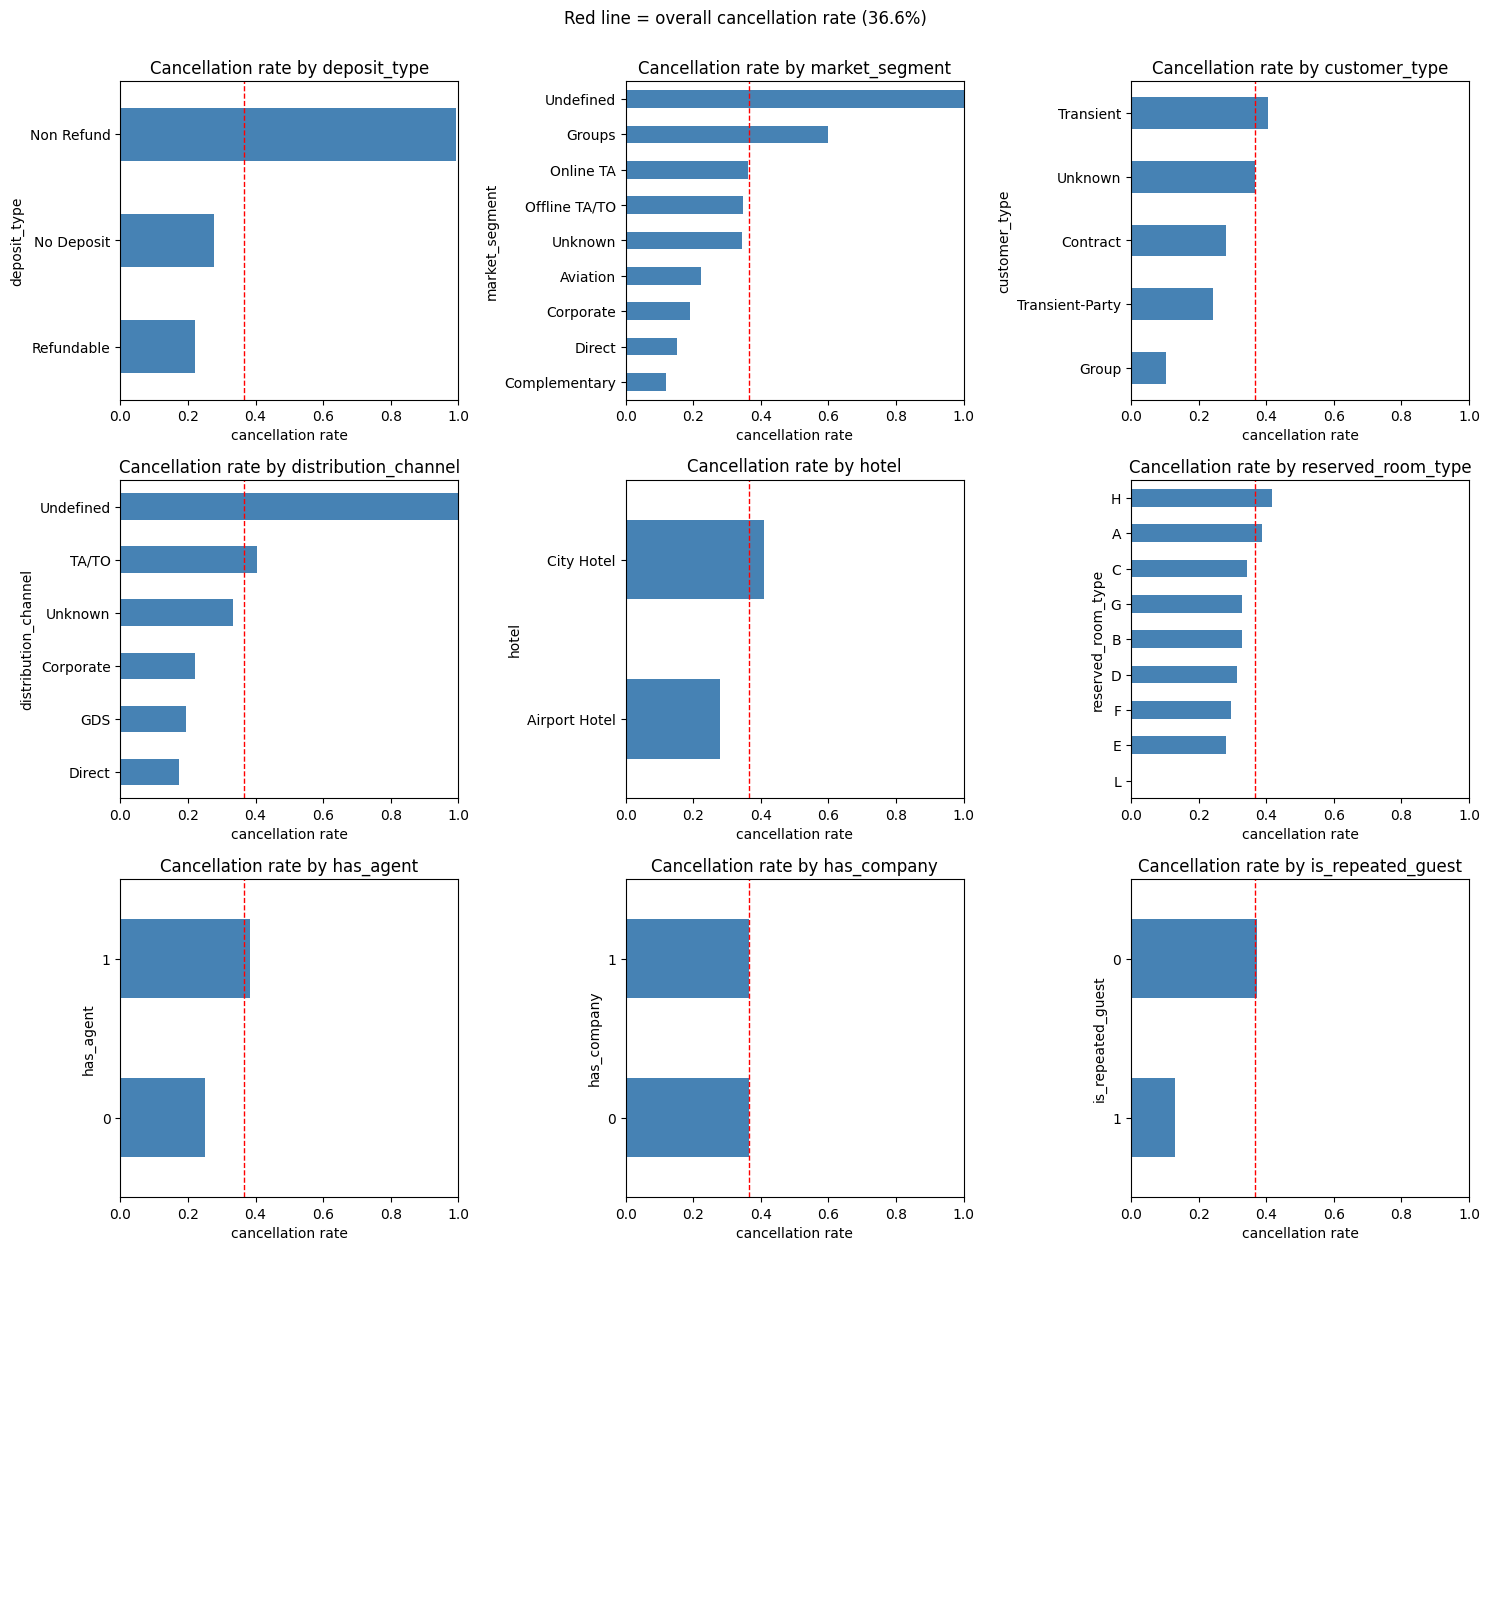

In [20]:
import matplotlib.pyplot as plt

base = df["is_canceled"].mean()
cats = ["deposit_type", "market_segment", "customer_type", "distribution_channel",
        "hotel", "reserved_room_type", "has_agent", "has_company",
        "is_repeated_guest"]

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, cats):
    rates = df.groupby(col)["is_canceled"].mean().sort_values()
    rates.plot.barh(ax=ax, color="steelblue")
    ax.axvline(base, color="red", ls="--", lw=1)
    ax.set_title(f"Cancellation rate by {col}")
    ax.set_xlim(0, 1)                      
    ax.set_xlabel("cancellation rate")     
for ax in axes.flat[len(cats):]:
    ax.axis("off")
fig.suptitle(f"Red line = overall cancellation rate ({base:.1%})", y=1.001)
plt.tight_layout()
plt.show()

In [21]:
print(df.groupby("required_car_parking_spaces")["is_canceled"].agg(["mean", "count"]))

                                 mean   count
required_car_parking_spaces                  
0                            0.389573  110123
1                            0.000000    7130
2                            0.000000      27
3                            0.000000       3
8                            0.000000       2


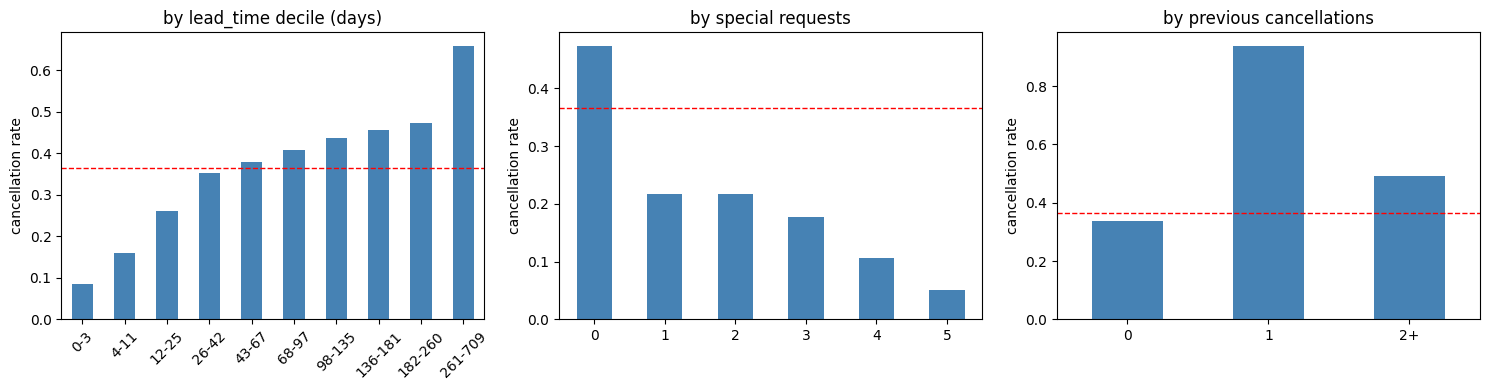

In [22]:
def fmt(interval):
    lo = 0 if interval.left < 0 else int(interval.left) + 1
    return f"{lo}-{int(interval.right)}"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

lead = df.groupby(pd.qcut(df["lead_time"], 10, duplicates="drop"),
                  observed=True)["is_canceled"].mean()
lead.index = [fmt(i) for i in lead.index]
lead.plot.bar(ax=axes[0], title="by lead_time decile (days)", color="steelblue", rot=45)

df.groupby("total_of_special_requests")["is_canceled"] \
  .mean().plot.bar(ax=axes[1], title="by special requests", color="steelblue", rot=0)

prev = df.groupby(df["previous_cancellations"].clip(upper=2))["is_canceled"].mean()
prev.index = ["0", "1", "2+"]
prev.plot.bar(ax=axes[2], title="by previous cancellations", color="steelblue", rot=0)

for ax in axes:
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_ylabel("cancellation rate")   
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Findings — what predicts cancellation**

All panels share a 0–1 scale, so bar lengths are directly comparable; the red line marks the overall 36.9% rate. Distance from that line indicates predictive strength.

- **lead_time is the strongest single signal.** Cancellation climbs monotonically from 8% for bookings made 0–3 days out to 66% for those made 263+ days ahead. Bookings made far in advance are low-commitment; those made days before arrival are near-certain to be honoured.

- **deposit_type is counterintuitive and needs care.** Non Refund bookings cancel at ~99% versus 26% for No Deposit. A non-refundable deposit should make guests *more* likely to arrive, so this almost certainly reflects a recording convention rather than guest behaviour — for example, the status may be applied once a booking is written off. The field is legitimately known at booking time, so it is retained as a feature, but its predictive power depends on that recording practice remaining unchanged. This is a known fragility, not a validated causal driver.

- **Booking channel matters and is actionable.** Group bookings cancel at ~60% against ~15% for Direct — a four-fold difference. Bookings made through an agent cancel at 39% versus 25% without. This supports deposit requirements on group bookings and incentives for direct booking, neither of which requires added rooms or staff.

- **Returning guests are roughly three times more reliable** — 13% versus 37% for first-timers.

- **Special requests indicate commitment.** Rate falls from 48% with no requests to 5% with five.

- **previous_cancellations is strong but non-monotonic** — 34% at zero, 93% at one, then 50% at two or more. The reversal is unexpected and likely relates to the sparse, irregular tail of that column noted during cleaning (values 13–26 with gaps). Retained as a feature, but flagged as a data-quality concern rather than treated as a clean behavioural signal.

- **City Hotel cancels at 41% versus Airport Hotel at 28%**, so `hotel` is retained.

- **has_company carries no signal** (36.3% vs 36.5%) and `reserved_room_type` spans only 29–41% with no actionable interpretation. Both are noted here and excluded from the model.

- **"Undefined" levels in market_segment and distribution_channel sit near 100%** but cover very few bookings; they are too small to interpret and are not treated as findings.

### Cancellation rate over time

A random split would mix future bookings into training. If the cancellation rate drifts over time, that split would overstate real-world performance; a time-based split (train 2023–24, test 2025) simulates deployment honestly.

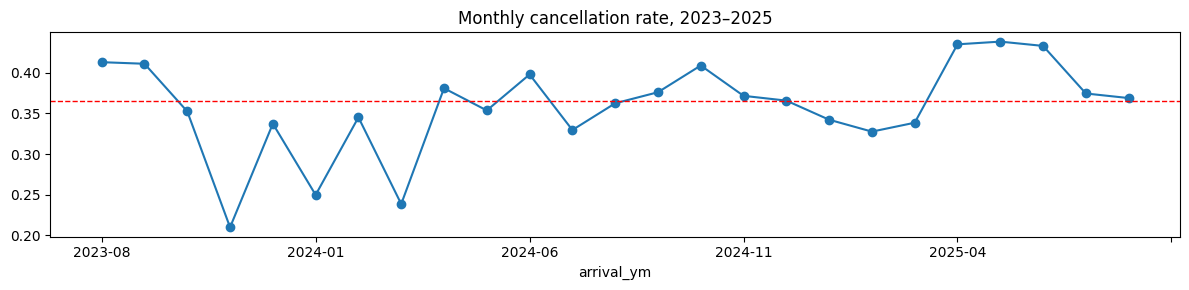

In [23]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
df["arrival_month_num"] = df["arrival_date_month"].map({m: i+1 for i, m in enumerate(month_order)})
df["arrival_ym"] = df["arrival_date_year"].astype(int).astype(str) + "-" + df["arrival_month_num"].astype(str).str.zfill(2)

df.groupby("arrival_ym")["is_canceled"].mean().plot(figsize=(12, 3), marker="o",
    title="Monthly cancellation rate, 2023–2025")
plt.axhline(base, color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

**Findings — cancellation rate over time**

The monthly rate is volatile throughout, ranging from ~21% (Nov 2023) to ~44% (May 2025), so no single month should be over-interpreted. The visible pattern is a raised block in April–June 2025 (~43–44%), which is the main driver of 2025's higher annual figure; July and August 2025 fall back to ~37%, close to the overall average.

### Pricing: where do rates look mis-set?

Second half of the problem statement. No pricing model is buildable from this data (no competitor rates, no demand curve, no counterfactual), so this is descriptive: where does pricing look inconsistent with demand? Proxy for demand: bookings per arrival date.

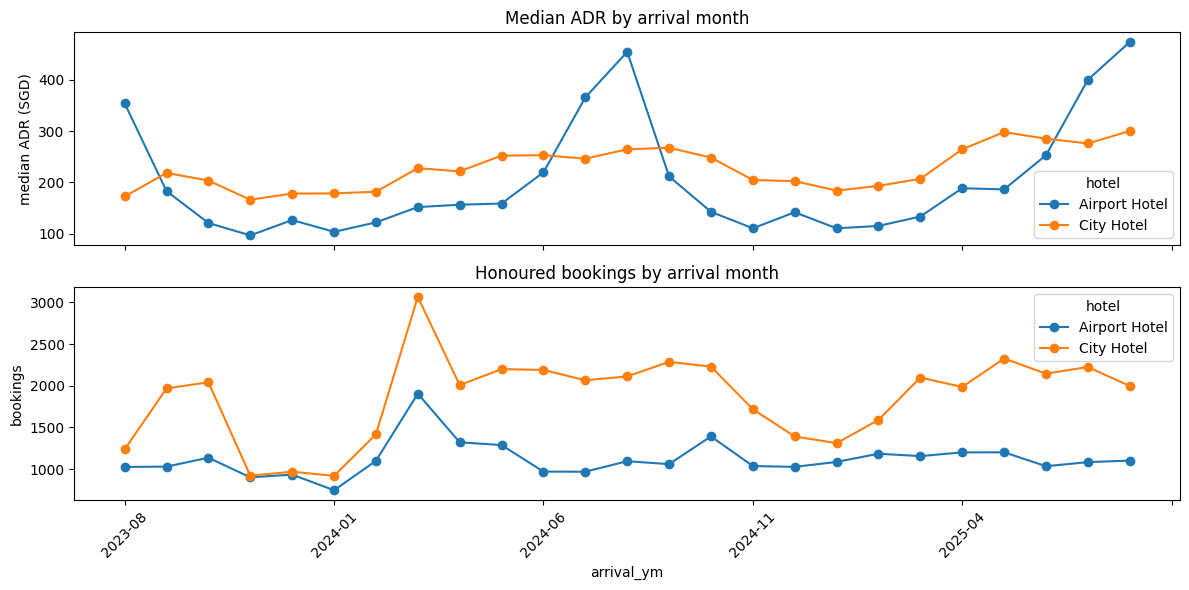

In [24]:
# Price and demand on a shared time axis — if price is flat while volume swings,
# that is the under-pricing evidence.
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# ADR = the rate set, so use all bookings (median, since ADR outliers were kept)
df.groupby(["arrival_ym", "hotel"])["adr"].median().unstack().plot(ax=axes[0], marker="o")
axes[0].set_title("Median ADR by arrival month")
axes[0].set_ylabel("median ADR (SGD)")

# Demand = rooms actually occupied, so use honoured bookings only
df[df["is_canceled"] == 0].groupby(["arrival_ym", "hotel"]).size().unstack().plot(ax=axes[1], marker="o")
axes[1].set_title("Honoured bookings by arrival month")
axes[1].set_ylabel("bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
print(pd.crosstab(df["hotel"], df["reservation_status"], normalize="index").round(4))

reservation_status  Canceled  Check-Out  No-Show
hotel                                           
Airport Hotel         0.2711     0.7217   0.0072
City Hotel            0.3977     0.5910   0.0113


In [26]:
monthly = df.groupby(["hotel", "arrival_ym"])["adr"].median().rename("median_adr").reset_index()
vol = df[df["is_canceled"] == 0].groupby(["hotel", "arrival_ym"]).size().rename("honoured").reset_index()
monthly = monthly.merge(vol, on=["hotel", "arrival_ym"])
for h, d in monthly.groupby("hotel"):
    print(h, "price-volume correlation:", round(d["median_adr"].corr(d["honoured"]), 3))

Airport Hotel price-volume correlation: -0.094
City Hotel price-volume correlation: 0.727


**Findings — pricing and property comparison**

**Airport Hotel is the more reliable property.** It cancels at 27.1% against City Hotel's 39.8%. No-shows are rare at both (0.7% and 1.1% of bookings respectively). The hypothesis that Airport Hotel would see disproportionate no-shows from travel disruption is not
supported — its no-show rate is the lower of the two on both absolute and relative measures.

**The two properties price very differently.** City Hotel's median ADR moves with demand: the correlation between monthly median ADR and honoured bookings is 0.73, across a $166–$300 range. Airport Hotel swings far harder — roughly $100 in November–February to $455–470 in
July–August, a 4.5x range — yet shows effectively no relationship to its own booking volume (correlation −0.09). This is not explained by capacity: Airport Hotel reached ~1,900 honoured bookings in March 2024 against a typical ~1,100, so it is not operating at a ceiling.

Airport Hotel is therefore the clearer pricing opportunity — large rate movements that do not track realised demand, matching the stakeholder's description of rates as "gut feel".

### Reviews table: usable for the model?

A post-stay review can only exist if the guest stayed. If review coverage is near zero for cancelled bookings, review-derived features would leak the outcome and the table cannot feed the model — only descriptive use is valid.

In [27]:
df["has_review"] = df["client_email"].isin(set(rv["client_email"])).astype(int)
print(df.groupby("is_canceled")["has_review"].mean().round(2))

# Descriptive: do expensive stays rate worse?
merged = df[df["is_canceled"] == 0].merge(rv[["client_email", "rating"]], on="client_email", how="inner")
print("\nMean rating by ADR quartile:")
quartiles = merged["adr"].quantile([0, 0.25, 0.5, 0.75, 1.0]).round().astype(int)
edges = quartiles.tolist()
labels = [f"${edges[i]}-{edges[i+1]}" for i in range(4)]
merged["adr_band"] = pd.cut(merged["adr"], bins=edges, labels=labels, include_lowest=True)
print(merged.groupby("adr_band", observed=True)["rating"].agg(["mean", "count"]).round(2))

is_canceled
0    0.23
1    0.00
Name: has_review, dtype: float64

Mean rating by ADR quartile:
           mean  count
adr_band              
$0-150     4.32   4287
$150-207   4.08   4322
$207-281   4.07   4185
$281-3123  3.89   4244


**Findings — reviews**

**Reviews cannot be used as model features.** No cancelled booking has a review (0.0%), against 23.0% of honoured bookings. This is structural — a post-stay review can only exist if the guest stayed — so any review-derived feature would perfectly identify the outcome.
The reviews table is excluded from the model and used descriptively only.

**Satisfaction falls as price rises.** Mean rating declines monotonically across ADR quartiles: 4.32 below $150, then 4.08, 4.07, and 3.89 above $281. With roughly 4,200 reviews per quartile, a gap of 0.42 points is well outside sampling noise. This supports the stakeholder's report of guests describing the hotels as expensive, and indicates perceived value-for-money weakens at higher rates.

This is an association only — the data cannot establish whether price causes lower ratings. It also covers honoured stays exclusively, so it says nothing about how guests who cancelled 5perceived the rates.

Airport Hotel is therefore the clearer pricing opportunity — large rate movements that do not
track realised demand, matching the stakeholder's description of rates as "gut feel". One
caveat: Airport Hotel's peak rates ($455-470) already sit in the ADR band where satisfaction
is lowest (mean rating 3.89 vs 4.32 at the bottom band), so any upward adjustment should be
tested carefully rather than pushed further in the same direction.vvvvy

## EDA conclusions and pipeline decisions

The dataset required substantial cleaning before analysis: 118,549 raw rows reduced to
117,285 after removing exact duplicates and rows with impossible values. Every cleaning
and feature decision below is implemented in `src/` and is reproducible by running the
pipeline.

### Data quality

| Finding | Evidence | Pipeline decision |
|---|---|---|
| Target stored under six encodings | `0`, `1`, `Yes`, `No`, `true`, `false` | Mapped to binary {0, 1} |
| All 36 columns stored as text | `df.info()` — every column `object` | Explicit numeric casting; `lead_time` contained text ("30 days"), digits extracted |
| Categorical values corrupted by case, spacing and typos | `meal` 41 levels (should be 5), `customer_type` 41 (4), `market_segment` 66 (8), `distribution_channel` 38 (5), `deposit_type` 26 (3) | Normaliser collapses variants to canonical sets; residual junk (1,776 rows) becomes an explicit "Unknown" level rather than being dropped or mode-imputed |
| Missing values stored as empty strings, invisible to `isna()` | `agent`, `company`, `promo_code` blank rather than null | Converted to NaN; `agent`/`company` replaced by `has_agent`/`has_company` flags |
| `country` mixed ISO codes, full names and junk | 140 levels including "Australia", "NULL", "Other" | Mapped to ISO; verified by regex that all values are 3-letter codes |
| `arrival_date_week_number` corrupt | 490 junk values (blank, "unknown", "-") | Dropped — redundant with month and day |
| 353 exact duplicate rows | Full-row duplicate check | Dropped |
| Impossible values | 187 zero-guest bookings, 625 zero-night stays, 100 lead times over 730 days | 911 rows dropped (0.77%) |
| Extreme ADR values retained | 1,229 bookings above $1,000, max $7,108 | Kept — Singapore suite rates plausibly exceed $1,000, and tree models split on rank rather than magnitude, so extremes do not distort them. Medians used for descriptive statistics |

### Target definition and leakage

| Finding | Evidence | Pipeline decision |
|---|---|---|
| `reservation_status` is the target re-encoded | Crosstab is perfectly diagonal: Check-Out → 74,384 honoured, Canceled + No-Show → 42,901 cancelled, zero off-diagonal | Excluded, with `reservation_status_date` |
| `assigned_room_type` is set at check-in | Bookings where assigned ≠ reserved cancel at 5.5% vs 40.7%, because a room can only be reassigned for a guest who arrived | Excluded |
| Reviews exist only for completed stays | 23% of honoured bookings have a review; 0% of cancelled ones do | Reviews excluded from the model entirely; used descriptively only |
| No-shows are a small share of the positive class | 1,164 of 42,901 (2.7%) | Single binary target: "booking not honoured" |

### Predictive signal

| Finding | Evidence | Pipeline decision |
|---|---|---|
| Class balance is moderate | 36.6% positive | `class_weight="balanced"`; no resampling needed |
| `lead_time` is the strongest single predictor | Monotonic 8% (0–3 days) to 66% (263+ days) | Retained; primary feature |
| `deposit_type` shows a counterintuitive pattern | Non Refund cancels at ~99% vs 26% for No Deposit | Retained, but flagged: this likely reflects a recording convention rather than guest behaviour, so its predictive value depends on that practice continuing |
| `previous_cancellations` is strong but non-monotonic | 34% (none), 93% (one), 50% (two or more) | Retained; the reversal relates to the sparse, irregular tail found during cleaning and is a data-quality caveat |
| Special requests indicate commitment | 48% with none, falling to 5% with five | Retained |
| The two properties differ substantially | City Hotel 40.9%, Airport Hotel 27.8% | `hotel` retained; one model covering both, so shared patterns learn from the full dataset |
| `has_company` carries no signal | 36.3% vs 36.5% | Retained but not interpreted |

### Validation strategy

| Finding | Evidence | Pipeline decision |
|---|---|---|
| Cancellation rates shifted between periods | On the eight months 2024 and 2025 share, the rate rose from 33.5% to 38.8%, with seven of eight months increasing | Time-based split (train 2023–24, test 2025). A random split would have mixed 2025 bookings into training, allowing the model to learn the higher rate and overstating deployment performance |
| Data coverage is uneven | 2023 has 5 months (Aug–Dec), 2024 has 12, 2025 has 8 (Jan–Aug) | Split gives 76,873 training and 40,412 test rows. Limitation accepted and recorded: September–December arrivals are absent from the test period, so performance on year-end bookings is untested |
| Base rate is not stable over time | Monthly rate ranges 21% to 44%, with a raised block in April–June 2025 | Deployment requires periodic retraining and threshold recalibration |

### Pricing (descriptive — no model built)

| Finding | Evidence | Conclusion |
|---|---|---|
| Airport Hotel's rates do not track demand | Correlation between monthly median ADR and honoured bookings: −0.09, despite a 4.5x seasonal price swing ($100 to $470) | The clearer pricing opportunity; matches the stakeholder's description of rates as "gut feel" |
| City Hotel's rates do track demand | Correlation 0.73 across a $166–$300 range | Directionally sound revenue management |
| Satisfaction declines as price rises | Mean rating 4.32 below $150, falling to 3.89 above $281 (~4,200 reviews per band) | Any upward rate adjustment at Airport Hotel should be trialled rather than applied broadly, since its peak rates already sit in the lowest-satisfaction band |
| No pricing model is possible from this data | No competitor rates, no room inventory, no record of prices offered but declined | Recommended next step: demand-linked rate setting at Airport Hotel, evaluated by controlled trial |

### Features used by the model

All columns are retained except those excluded above (`reservation_status`, `reservation_status_date`, `assigned_room_type`, `client_email`, `booking_id`, `arrival_date_week_number`, `agent`, `company`, and the reviews table). Categorical features are one-hot encoded with rare levels grouped; numeric features are median-imputed and scaled. All transformations are fitted on the training split only and applied to the test split, so no test-set information influences training.